In [69]:
#### Initialization
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

###Implement equations of motion into state vector and its derivative

def dynamics(t,X,tau, params):

    m = params["m"]
    g = params["g"]
    L = params["L"]
    Ixx = params["Ixx"]
    Iyy = params["Iyy"]
    Izz = params["Izz"]
    kF = params["kF"]
    kM = params["kM"]
    Jr = params["Jr"]
    
    x,y,z = X[0:3]

    xdot, ydot, zdot = X[3:6]

    phi, theta, psi = X[6:9]

    p, q, r = X[9:12]

    omega1, omega2, omega3, omega4 = X[12:16]

    Xdot = np.zeros(16)

    ###Translational Dynamics

    Xdot[0:3] = [xdot, ydot, zdot]

    F1 = kF * omega1**2
    F2 = kF * omega2**2
    F3 = kF * omega3**2
    F4 = kF * omega4**2

    M1 = kM * omega1**2
    M2 = kM * omega2**2
    M3 = kM * omega3**2
    M4 = kM * omega4**2

    gamma = kM/kF

    T = F1 + F2 + F3 + F4

    xddot = (T/m)*(np.sin(theta)*np.cos(phi)*np.cos(psi) + np.sin(psi)*np.sin(phi))

    yddot = (T/m)*(np.sin(theta)*np.cos(phi)*np.sin(psi) - np.cos(psi)*np.sin(phi))

    zddot = (T/m)*np.cos(theta)*np.cos(phi) - g

    Xdot[3:6] = [xddot, yddot, zddot]

    ###Rotational Dynamics

    pdot = (L*kF*(omega2**2 - omega4**2) + q*r*(Iyy - Izz)) / Ixx

    qdot = (L*kF*(omega3**2 - omega1**2) + r*p*(Izz - Ixx)) / Iyy

    rdot = (kM*(omega1**2 - omega2**2 + omega3**2 - omega4**2) + p*q*(Ixx - Iyy)) / Izz

    Xdot[9:12] = [pdot, qdot, rdot]

    phidot = p + q*np.sin(phi)*np.tan(theta) + r*np.cos(phi)*np.tan(theta)

    thetadot = q*np.cos(phi) - r*np.sin(phi)

    psidot = (q*np.sin(phi) + r*np.cos(phi))/(np.cos(theta))

    Xdot[6:9] = [phidot, thetadot, psidot]

    ### Rotor Dynamics

    omega1dot = (tau[0] - kM*omega1**2) / Jr
    omega2dot = (tau[1] - kM*omega2**2) / Jr
    omega3dot = (tau[2] - kM*omega3**2) / Jr
    omega4dot = (tau[3] - kM*omega4**2) / Jr

    Xdot[12:16] = [omega1dot, omega2dot, omega3dot, omega4dot]
    
    return Xdot







def plot_6dof(sol, title, filename):

    fig, axs = plt.subplots(2, 3, figsize=(14, 8), sharex=True)

    positions = ["$x$", "$y$", "$z$"]
    angles = [r"Roll ($\phi$)", r"Pitch ($\theta$)", r"Yaw ($\psi$)"]

    # Shared position limits
    pos_min = np.min(sol.y[0:3])
    pos_max = np.max(sol.y[0:3])
    pos_pad = max(0.1*(pos_max - pos_min), 0.1)

    # Shared angle limits
    angle_data = np.degrees(sol.y[6:9])
    angle_data[2] = angle_data[2] % 360
    angle_min = np.min(angle_data)
    angle_max = np.max(angle_data)
    angle_pad = max(0.1*(angle_max - angle_min), 5.0)

    for i in range(3):
        # Position
        axs[0, i].plot(sol.t, sol.y[i])
        axs[0, i].set_title(f"{positions[i]} Position", fontsize=20)
        axs[0, i].set_xlabel("Time (s)")
        axs[0, i].set_ylim(pos_min - pos_pad, pos_max + pos_pad)
        axs[0, i].grid(True)

        # Euler angles
        axs[1, i].plot(sol.t, angle_data[i])
        axs[1, i].set_title(angles[i], fontsize=20)
        axs[1, i].set_xlabel("Time (s)")
        axs[1, i].set_ylim(angle_min - angle_pad, angle_max + angle_pad)
        axs[1, i].grid(True)

    axs[0, 0].set_ylabel("Position (m)", fontsize=18)
    axs[1, 0].set_ylabel("Euler Angle (deg)", fontsize=18)

    for ax in axs.flat:
        ax.tick_params(axis="both", labelsize=15)
        ax.tick_params(axis="x", labelbottom=True)
        ax.set_xlim(sol.t[0], sol.t[-1])

    fig.suptitle(title, fontsize=25)
    plt.tight_layout()
    fig.savefig(filename, bbox_inches="tight")
    plt.show()






In [ ]:
###Physical Parameters

params = {
    "m": 1.5,
    "g": 9.81,
    "L": 0.22,
    "Ixx": 0.018,
    "Iyy": 0.018,
    "Izz": 0.030,
    "kF": 1.0e-5,
    "kM": 1.5e-7,
    "Jr": 8.0e-5
}



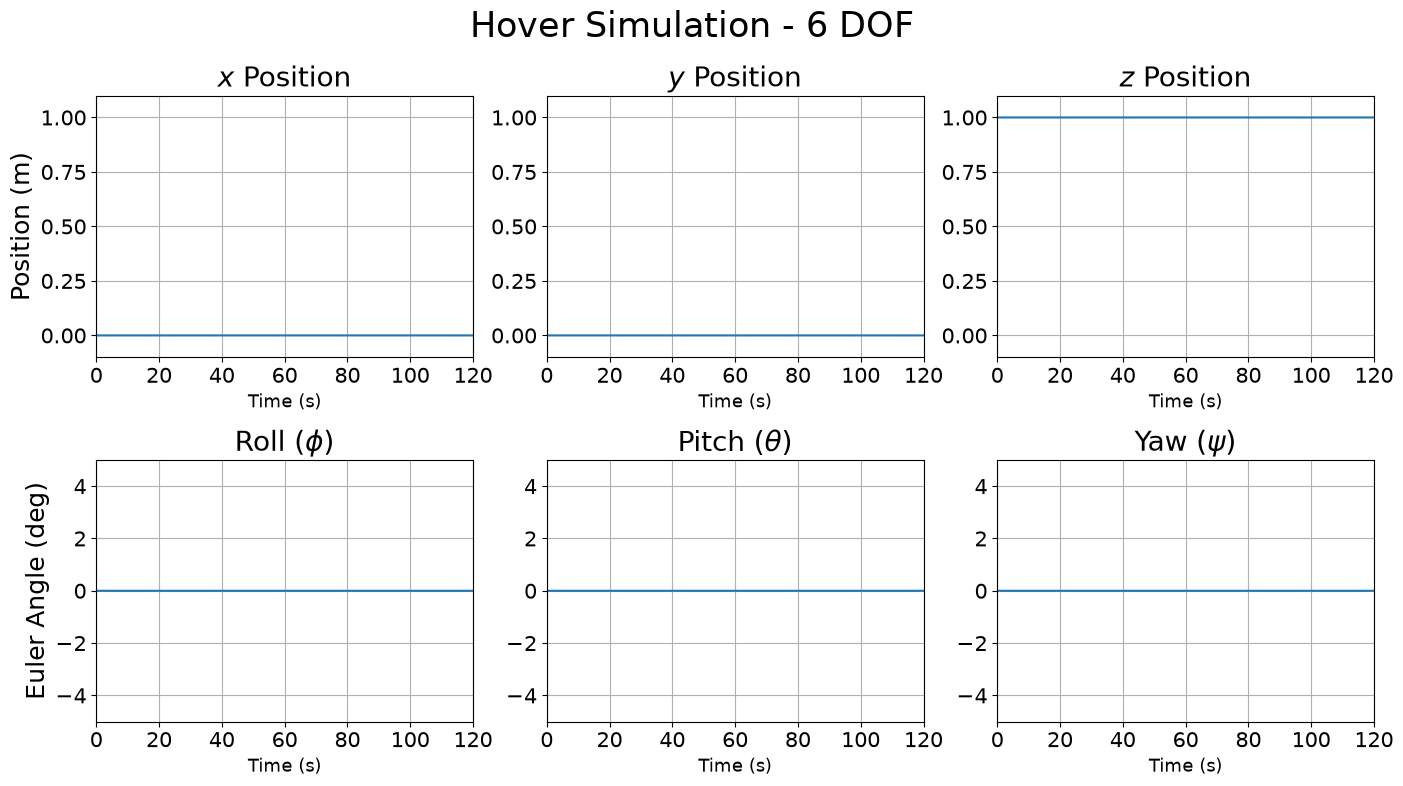

In [66]:
###Hover Case
# Equilibrium hover conditions

omega_hover = np.sqrt(
    params["m"] * params["g"] / (4 * params["kF"])
)

tau_hover = params["kM"] * omega_hover**2

X0_hover = np.zeros(16)

X0_hover[2] = 1
X0_hover[12:16] = omega_hover

tau_hover_array = np.full(4, tau_hover)

timespan_hover = (0,120)

sol_hover = solve_ivp(
    fun=lambda t, X: dynamics(t, X, tau_hover_array, params),
    t_span=timespan_hover,
    y0=X0_hover,
    method="RK45",
    t_eval=np.linspace(0, 120, 1201),
    rtol=1e-8,
    atol=1e-10
)

plot_6dof(sol_hover, "Hover Simulation - 6 DOF", "hover_6dof.pdf")



In [9]:
print("Initial altitude:", sol_hover.y[2, 0])
print("Final altitude:", sol_hover.y[2, -1])
print("Minimum altitude:", np.min(sol_hover.y[2]))
print("Maximum altitude error:", np.max(np.abs(sol_hover.y[2] - 1.0)))

Initial altitude: 1.0
Final altitude: 0.9999999999744204
Minimum altitude: 0.9999999999744204
Maximum altitude error: 2.557964950966607e-11


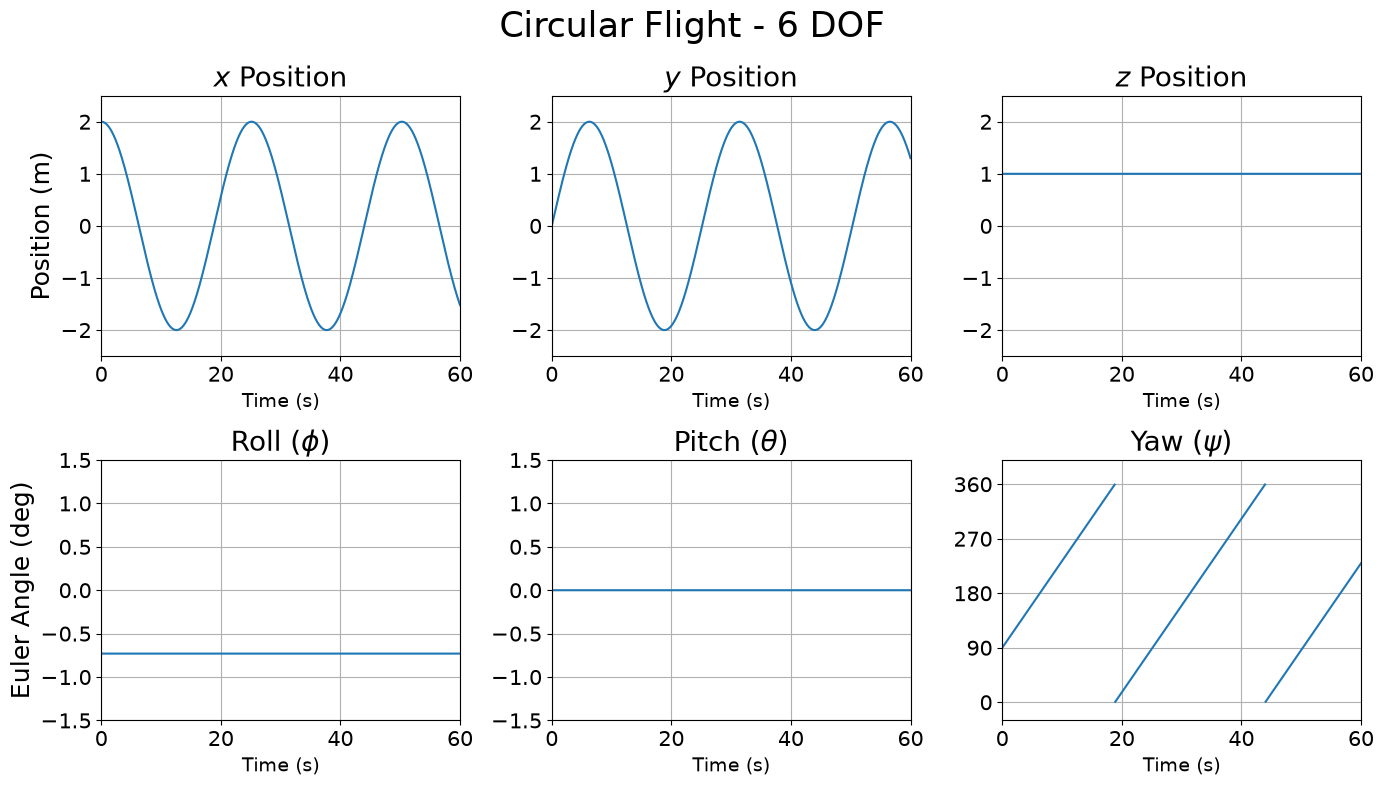

In [72]:
### Performance Test 2: Circular Flight

R_circle = 2.0
v_circle = 0.5
z_circle = 1.0

Omega_circle = v_circle / R_circle
ac_circle = v_circle**2 / R_circle

# Required inward bank angle
phi_circle = -np.arctan(ac_circle / params["g"])

# Initial state
X0_circle = np.zeros(16)

# Initial position
X0_circle[0:3] = [R_circle, 0, z_circle]

# Initial translational velocity
X0_circle[3:6] = [0, v_circle, 0]

# Initial orientation
X0_circle[6:9] = [phi_circle, 0, np.pi/2]

# Initial body angular velocity
X0_circle[9:12] = [
    0,
    Omega_circle*np.sin(phi_circle),
    Omega_circle*np.cos(phi_circle)
]
### Circular Flight Rotor Speeds

T_circle = params["m"] * params["g"] / np.cos(phi_circle)

q0 = X0_circle[10]
r0 = X0_circle[11]

omega_sq = np.array([
    T_circle / (4 * params["kF"]),

    T_circle / (4 * params["kF"])
    + q0*r0*(params["Izz"] - params["Iyy"])
    / (2 * params["L"] * params["kF"]),

    T_circle / (4 * params["kF"]),

    T_circle / (4 * params["kF"])
    - q0*r0*(params["Izz"] - params["Iyy"])
    / (2 * params["L"] * params["kF"])
])

assert np.all(omega_sq >= 0)

omega_circle = np.sqrt(omega_sq)

X0_circle[12:16] = omega_circle

### Circular Flight Motor Torques

tau_circle = params["kM"] * omega_circle**2

t_span_circle = (0, 60)

sol_circle = solve_ivp(
    fun=lambda t, X: dynamics(t, X, tau_circle, params),
    t_span=t_span_circle,
    y0=X0_circle,
    method="RK45",
    t_eval=np.linspace(0, 60, 1201),
    rtol=1e-8,
    atol=1e-10
)


# Circular Flight - 6 DOF Plots


# Circular Flight - 6 DOF Plots

fig, axs = plt.subplots(2, 3, figsize=(14, 8))

t = sol_circle.t
positions = sol_circle.y[0:3]
angles = np.degrees(sol_circle.y[6:9])

# Wrap yaw between 0 and 360 degrees
yaw = angles[2] % 360

# Break the line at yaw wraparound to avoid vertical jumps
yaw_plot = yaw.copy()
yaw_plot[np.where(np.abs(np.diff(yaw)) > 180)[0] + 1] = np.nan

# Position plots
position_titles = ["$x$ Position", "$y$ Position", "$z$ Position"]

for i in range(3):
    axs[0, i].plot(t, positions[i])
    axs[0, i].set_title(position_titles[i], fontsize=20)
    axs[0, i].set_ylim(-2.5, 2.5)
    axs[0, i].grid(True)

# Euler angle plots
angle_titles = [r"Roll ($\phi$)", r"Pitch ($\theta$)", r"Yaw ($\psi$)"]

for i in range(3):
    data = yaw_plot if i == 2 else angles[i]
    axs[1, i].plot(t, data)
    axs[1, i].set_title(angle_titles[i], fontsize=20)
    axs[1, i].grid(True)

    if i < 2:
        axs[1, i].set_ylim(-1.5, 1.5)
    else:
        axs[1, i].set_ylim(-30, 400)
        axs[1, i].set_yticks([0, 90, 180, 270, 360])

# Y-axis labels
axs[0, 0].set_ylabel("Position (m)", fontsize=18)
axs[1, 0].set_ylabel("Euler Angle (deg)", fontsize=18)

# Formatting for all six plots
for ax in axs.flat:
    ax.set_xlabel("Time (s)", fontsize=14)
    ax.set_xlim(t[0], t[-1])
    ax.set_xticks(np.arange(0, 61, 20))
    ax.tick_params(axis="both", labelsize=15)

fig.suptitle("Circular Flight - 6 DOF", fontsize=25)

plt.tight_layout()
fig.savefig("circle_6dof.pdf", bbox_inches="tight")
plt.show()



In [56]:
print("Roll:", np.degrees(sol_circle.y[6, 0]))
print("Pitch:", np.degrees(sol_circle.y[7, 0]))
print("Yaw:", np.degrees(sol_circle.y[8, 0]))

print("Final roll:", np.degrees(sol_circle.y[6, -1]))
print("Final pitch:", np.degrees(sol_circle.y[7, -1]))

Roll: -0.7300290385619328
Pitch: 0.0
Yaw: 90.0
Final roll: -0.7300290385769308
Final pitch: -4.89333101716528e-12


Initial speed: 0.5 m/s
Final speed: 0.500000000024143 m/s
Average speed: 0.49999999996461186 m/s
Maximum speed error: 2.9216640218265866e-10 m/s


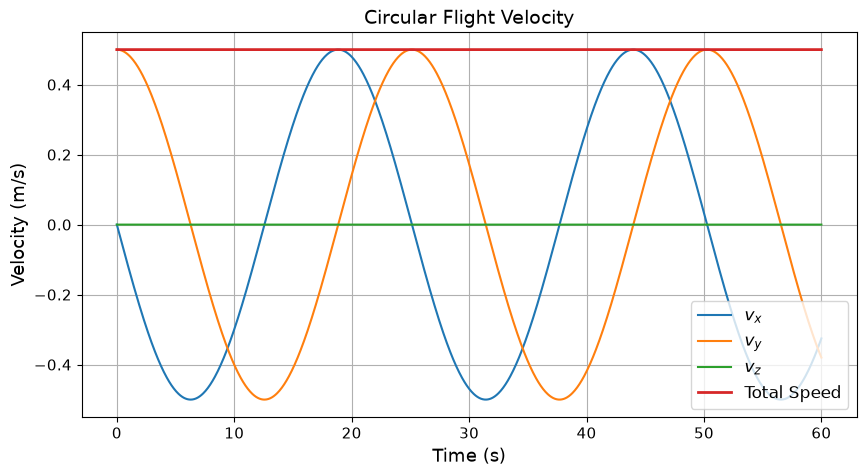

In [57]:
vx = sol_circle.y[3]
vy = sol_circle.y[4]
vz = sol_circle.y[5]

speed = np.sqrt(vx**2 + vy**2 + vz**2)

print("Initial speed:", speed[0], "m/s")
print("Final speed:", speed[-1], "m/s")
print("Average speed:", np.mean(speed), "m/s")
print("Maximum speed error:", np.max(np.abs(speed - 0.5)), "m/s")
plt.figure(figsize=(10, 5))

plt.plot(sol_circle.t, vx, label="$v_x$")
plt.plot(sol_circle.t, vy, label="$v_y$")
plt.plot(sol_circle.t, vz, label="$v_z$")
plt.plot(sol_circle.t, speed, label="Total Speed", linewidth=2)

plt.xlabel("Time (s)")
plt.ylabel("Velocity (m/s)")
plt.title("Circular Flight Velocity")
plt.legend()
plt.grid(True)
plt.show()

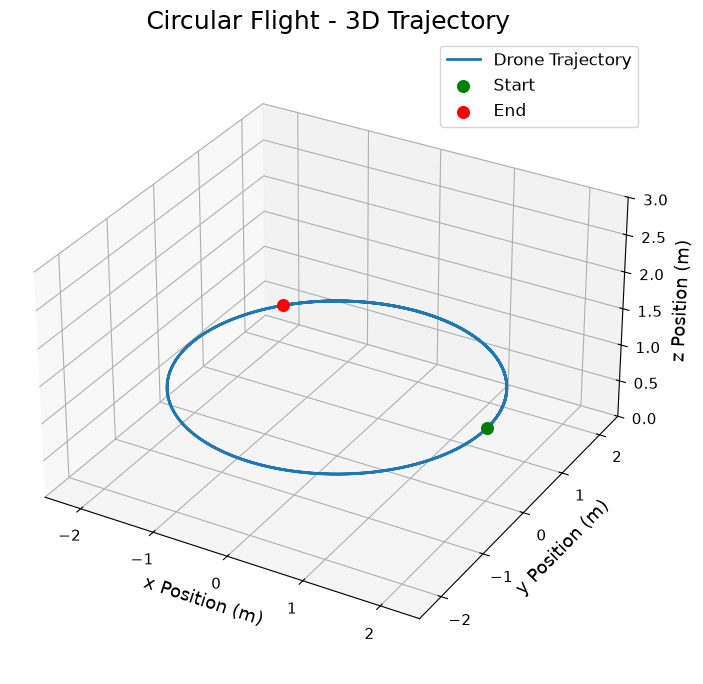

In [59]:

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

# Plot the 3D trajectory
ax.plot(
    sol_circle.y[0],
    sol_circle.y[1],
    sol_circle.y[2],
    linewidth=2,
    label="Drone Trajectory"
)

# Mark initial and final positions
ax.scatter(*sol_circle.y[0:3, 0], color="green", s=70, label="Start")
ax.scatter(*sol_circle.y[0:3, -1], color="red", s=70, label="End")

# Set axis limits
ax.set_xlim(-2.5, 2.5)
ax.set_ylim(-2.5, 2.5)
ax.set_zlim(0, 3)

# Set axis scaling proportional to physical dimensions
ax.set_box_aspect((5, 5, 3))

# Labels
ax.set_xlabel("x Position (m)", fontsize=13)
ax.set_ylabel("y Position (m)", fontsize=13)
ax.set_zlabel("z Position (m)", fontsize=13)

ax.set_title("Circular Flight - 3D Trajectory", fontsize=18)
ax.legend()

plt.tight_layout()
plt.savefig("circle_3d.pdf", bbox_inches="tight")
plt.show()
